# CA2: Global Digital Transformation Readiness
**A Longitudinal Statistical Assessment of Digital Infrastructure and Technology Development Across Countries (2010–2024)**

* **Student Name / ID:** Jose Guadalupe Briones Acevedo (2026739)
* **Module:** Statistical Techniques for Data Analysis
* **Institution:** CCT College Dublin
* **GitHub Repository:** https://github.com/2026739-Jose/CA-1-Capstone-Project_Stats-for-Data-Analytics/tree/main/CA2
* **Video Presentation (Google Drive):** *Link*

## 1. Research Design

### 1.1 Project Identity and Business Problem
* **Domain:** Technology & Digital Transformation (Project Management Perspective)
* **Scope & Unit of Analysis:** Global country-year longitudinal panel (`2010–2024`)
* **Primary Data Source:** World Bank – World Development Indicators (WDI), observational data
* **Analytical Approach:** Descriptive statistics, confidence intervals, parametric and non-parametric hypothesis testing, and panel regression analysis in Python.

**Business Problem:**  
International organizations planning digital transformation initiatives across multiple countries face substantial financial, operational, and adoption risks when entering markets with underdeveloped technological foundations. From a **Project Management** standpoint, committing capital without assessing national digital readiness increases the risk of project delays, cost overruns, and low user adoption. This study evaluates how digital infrastructure and technological readiness have evolved across countries and geographic regions between 2010 and 2024, providing empirical evidence to support market prioritization and risk mitigation strategies—rather than claiming any single country is universally optimal.

### 1.2 Research Question
> *How has digital infrastructure readiness evolved across countries and regions, and which economic and technological factors are associated with its development over time?*

### 1.3 Specific Objectives
1. **Describe** the longitudinal evolution of key digital infrastructure and technology indicators across countries from 2010 to 2024.
2. **Compare** technological progress and infrastructure gaps across geographic regions and five-year periods (`2010–2014` vs. `2020–2024`).
3. **Examine** statistically significant differences between time periods and country groups using formal parametric and non-parametric hypothesis tests.
4. **Investigate** statistical associations between digital infrastructure expansion, innovation capacity (R&D), and economic development (GDP per capita).
5. **Translate** empirical findings into actionable Project Management recommendations for planning, prioritizing, and de-risking international digital transformation projects.

### 1.4 General Research Hypotheses
To guide the subsequent statistical testing phase (once data coverage is audited), this study formulates five core hypotheses:
* **H1 (Temporal Evolution):** Digital adoption (internet penetration) and connectivity (fixed broadband) increased significantly between the initial period (`2010–2014`) and the recent period (`2020–2024`).
* **H2 (Regional Disparities):** The magnitude of digital infrastructure growth differs significantly across global geographic regions.
* **H3 (Categorical Independence):** A country's geographic region is statistically associated with its level of digital improvement (e.g., low, moderate, or high growth tier).
* **H4 (Innovation Association):** Gains in digital connectivity are positively associated with changes in national Research and Development (R&D) expenditure.
* **H5 (Economic & Structural Drivers):** Within-country improvements in digital infrastructure over time are significantly associated with economic development (GDP per capita) and ICT sector activity, after controlling for country-specific and time-specific effects.

## 2. Data Source Verification & Initial Audit

### 2.1 Official Source and Indicators
All primary indicators and country metadata are retrieved programmatically from the **World Bank World Development Indicators (WDI) API v2** (`https://api.worldbank.org/v2`), which provides open access without authentication. To ensure reproducibility, raw API responses are saved in `data/raw/` before any filtering or aggregation.

* **Numeric Indicators (`2010–2024`):**
  * `IT.NET.USER.ZS`: Individuals using the Internet (% of population) — *Digital adoption*
  * `IT.NET.BBND.P2`: Fixed broadband subscriptions (per 100 people) — *Connectivity infrastructure*
  * `IT.NET.SECR.P6`: Secure Internet servers (per 1 million people) — *Secure digital infrastructure*
  * `BX.GSR.CCIS.ZS`: ICT service exports (% of service exports) — *ICT economic participation*
  * `GB.XPD.RSDV.GD.ZS`: Research and development expenditure (% of GDP) — *Innovation capacity*
  * `NY.GDP.PCAP.KD`: GDP per capita (constant 2015 US$) — *Economic context / control*
* **Categorical & Identifier Fields:** `country_code`, `country_name`, `region`, `income_group`, and `year` (obtained from official World Bank metadata, excluding regional/income aggregates).

In [1]:
import os
import numpy as np
import pandas as pd
import requests

# Ensure project directories exist relative to notebooks/
RAW_DIR = "../data/raw"
PROCESSED_DIR = "../data/processed"
os.makedirs(RAW_DIR, exist_ok=True)
os.makedirs(PROCESSED_DIR, exist_ok=True)

BASE_URL = "https://api.worldbank.org/v2"
START_YEAR = 2010
END_YEAR = 2024

INDICATORS = {
    "internet_users": "IT.NET.USER.ZS",
    "fixed_broadband": "IT.NET.BBND.P2",
    "secure_servers": "IT.NET.SECR.P6",
    "ict_exports": "BX.GSR.CCIS.ZS",
    "rd_expenditure": "GB.XPD.RSDV.GD.ZS",
    "gdp_per_capita": "NY.GDP.PCAP.KD",
}


def fetch_country_metadata() -> pd.DataFrame:
  """Fetch official country metadata from World Bank API v2, excluding aggregates."""
  url = f"{BASE_URL}/country"
  params = {"format": "json", "per_page": 500}
  response = requests.get(url, params=params, timeout=60)
  response.raise_for_status()
  payload = response.json()

  records = []
  for item in payload[1]:
    region_info = item.get("region", {})
    income_info = item.get("incomeLevel", {})
    # Filter out non-country aggregates (coded with region id == "NA")
    if region_info.get("id") == "NA":
      continue
    records.append({
        "country_code": item["id"],
        "country_name": item["name"],
        "region": region_info.get("value"),
        "income_group": income_info.get("value"),
    })
  return pd.DataFrame(records).drop_duplicates(subset=["country_code"])


def fetch_indicator_series(alias: str, indicator_code: str) -> pd.DataFrame:
  """Fetch annual indicator values across all entities for the target year range."""
  url = f"{BASE_URL}/country/all/indicator/{indicator_code}"
  params = {
      "date": f"{START_YEAR}:{END_YEAR}",
      "format": "json",
      "per_page": 25000,
  }
  response = requests.get(url, params=params, timeout=60)
  response.raise_for_status()
  payload = response.json()

  rows = [
      {
          "country_code": entry.get("countryiso3code"),
          "year": int(entry["date"]),
          alias: entry.get("value"),
      }
      for entry in payload[1]
      if entry.get("countryiso3code")
  ]
  return pd.DataFrame(rows)


# 1. Download metadata and save raw snapshot
metadata_df = fetch_country_metadata()
metadata_df.to_csv(f"{RAW_DIR}/country_metadata.csv", index=False)

# 2. Download each WDI indicator and merge on country_code and year
series_dfs = [
    fetch_indicator_series(alias, code) for alias, code in INDICATORS.items()
]
panel_raw = series_dfs[0]
for df_part in series_dfs[1:]:
  panel_raw = panel_raw.merge(df_part, on=["country_code", "year"], how="outer")

# Attach official country metadata (inner join keeps individual countries only)
panel_raw = panel_raw.merge(metadata_df, on="country_code", how="inner")
ordered_cols = [
    "country_code",
    "country_name",
    "region",
    "income_group",
    "year",
    *INDICATORS.keys(),
]
panel_raw = (
    panel_raw[ordered_cols]
    .sort_values(["country_code", "year"])
    .reset_index(drop=True)
)
panel_raw.to_csv(f"{RAW_DIR}/wdi_indicators_raw.csv", index=False)

print(
    f"Countries: {panel_raw['country_code'].nunique()} | Total country-year"
    f" rows: {len(panel_raw)}"
)

# 3. Audit indicator coverage overall and across comparative 5-year periods
early_years = set(range(2010, 2015))
recent_years = set(range(2020, 2025))

audit_rows = []
for col in INDICATORS.keys():
  valid_mask = panel_raw[col].notna()
  non_null_count = int(valid_mask.sum())
  coverage_pct = round((non_null_count / len(panel_raw)) * 100, 2)
  countries_avail = panel_raw.loc[valid_mask, "country_code"].nunique()

  early_countries = set(
      panel_raw.loc[
          valid_mask & panel_raw["year"].isin(early_years), "country_code"
      ]
  )
  recent_countries = set(
      panel_raw.loc[
          valid_mask & panel_raw["year"].isin(recent_years), "country_code"
      ]
  )
  paired_count = len(early_countries & recent_countries)

  audit_rows.append({
      "indicator": col,
      "non_null_rows": non_null_count,
      "coverage_pct": coverage_pct,
      "countries_with_data": countries_avail,
      "paired_countries_2010_14_vs_2020_24": paired_count,
  })

audit_summary = pd.DataFrame(audit_rows)
display(audit_summary)

Countries: 217 | Total country-year rows: 3255


,indicator,non_null_rows,coverage_pct,countries_with_data,paired_countries_2010_14_vs_2020_24
0,internet_users,2894,88.91,209,187
1,fixed_broadband,2900,89.09,208,207
2,secure_servers,3193,98.10,215,213
3,ict_exports,2643,81.20,189,174
4,rd_expenditure,1310,40.25,143,99
5,gdp_per_capita,3122,95.91,213,208


## 3. Data Audit & Longitudinal Dataset Preparation

Before running inferential tests or regression models, we audit data availability across countries, years, and five-year comparison windows (`2010–2014` vs. `2020–2024`). Following longitudinal best practices, repeated country-year observations are preserved for panel analysis, while period-over-period comparisons compute five-year means ($\Delta \overline{X} = \overline{X}_{2020\text{-}24} - \overline{X}_{2010\text{-}24}$) only for countries meeting a minimum coverage threshold in both windows.

In [5]:
import numpy as np
import pandas as pd

RAW_DIR = "../data/raw"
PROCESSED_DIR = "../data/processed"

panel_raw = pd.read_csv(f"{RAW_DIR}/wdi_indicators_raw.csv")
indicator_cols = [
    "internet_users",
    "fixed_broadband",
    "secure_servers",
    "ict_exports",
    "rd_expenditure",
    "gdp_per_capita",
]

EARLY_YEARS = list(range(2010, 2015))  # 2010-2014
RECENT_YEARS = list(range(2020, 2025))  # 2020-2024
MIN_OBS_PER_PERIOD = 2

# 1. Detailed coverage audit per indicator
audit_records = []
total_rows = len(panel_raw)

for col in indicator_cols:
  valid = panel_raw[panel_raw[col].notna()]
  early_counts = (
      panel_raw[panel_raw["year"].isin(EARLY_YEARS)]
      .groupby("country_code")[col]
      .count()
  )
  recent_counts = (
      panel_raw[panel_raw["year"].isin(RECENT_YEARS)]
      .groupby("country_code")[col]
      .count()
  )

  paired_countries = set(
      early_counts[early_counts >= MIN_OBS_PER_PERIOD].index
  ) & set(recent_counts[recent_counts >= MIN_OBS_PER_PERIOD].index)

  audit_records.append({
      "indicator": col,
      "valid_obs": len(valid),
      "missing_pct": round((1 - len(valid) / total_rows) * 100, 2),
      "countries_any_year": valid["country_code"].nunique(),
      "paired_countries_min2_per_window": len(paired_countries),
  })

audit_df = pd.DataFrame(audit_records)
print("=== Indicator Coverage Audit (2010-2024) ===")
display(audit_df)

# 2. Compute five-year period means and changes (Delta = 2020-2024 minus 2010-2014)
meta_cols = ["country_code", "country_name", "region", "income_group"]
period_summary = panel_raw[meta_cols].drop_duplicates().copy()

for col in indicator_cols:
  early_stats = (
      panel_raw[panel_raw["year"].isin(EARLY_YEARS)]
      .groupby("country_code")[col]
      .agg(early_mean="mean", early_n="count")
      .reset_index()
  )
  recent_stats = (
      panel_raw[panel_raw["year"].isin(RECENT_YEARS)]
      .groupby("country_code")[col]
      .agg(recent_mean="mean", recent_n="count")
      .reset_index()
  )

  merged = early_stats.merge(recent_stats, on="country_code", how="outer")
  valid_pair = (merged["early_n"] >= MIN_OBS_PER_PERIOD) & (
      merged["recent_n"] >= MIN_OBS_PER_PERIOD
  )

  merged[f"{col}_2010_14"] = np.where(valid_pair, merged["early_mean"], np.nan)
  merged[f"{col}_2020_24"] = np.where(valid_pair, merged["recent_mean"], np.nan)
  merged[f"{col}_delta"] = (
      merged[f"{col}_2020_24"] - merged[f"{col}_2010_14"]
  )

  keep_cols = [
      "country_code",
      f"{col}_2010_14",
      f"{col}_2020_24",
      f"{col}_delta",
  ]
  period_summary = period_summary.merge(
      merged[keep_cols], on="country_code", how="left"
  )

# Save annual panel and five-year period comparison dataset
panel_raw.to_csv(
    f"{PROCESSED_DIR}/digital_transformation_panel.csv", index=False
)
period_summary.to_csv(
    f"{PROCESSED_DIR}/period_comparison_2010_2024.csv", index=False
)

print(
    "\nSaved processed datasets to"
    f" {PROCESSED_DIR}/digital_transformation_panel.csv and"
    " period_comparison_2010_2024.csv"
)

=== Indicator Coverage Audit (2010-2024) ===


,indicator,valid_obs,missing_pct,countries_any_year,paired_countries_min2_per_window
0,internet_users,2894,11.09,209,182
1,fixed_broadband,2900,10.91,208,204
2,secure_servers,3193,1.90,215,212
3,ict_exports,2643,18.80,189,170
4,rd_expenditure,1310,59.75,143,80
5,gdp_per_capita,3122,4.09,213,208



Saved processed datasets to ../data/processed/digital_transformation_panel.csv and period_comparison_2010_2024.csv


## 4. Exploratory Data Analysis (EDA)

This section explores distributional characteristics, regional patterns, and temporal trajectories across the longitudinal dataset (`2010–2024`) and five-year period shifts (`2010–2014` vs. `2020–2024`). Examining skewness, spread, and regional differences here informs both our statistical test selection and our Project Management interpretation of digital readiness gaps.

=== Longitudinal Panel Descriptive Statistics (2010-2024) ===


,count,mean,median,std,min,max
internet_users,2894.0,53.87,58.58,30.21,0.25,100.00
fixed_broadband,2900.0,14.44,9.49,14.57,0.00,75.75
secure_servers,3193.0,11138.41,207.51,85191.79,0.00,3262663.43
ict_exports,2643.0,8.85,5.43,10.10,0.00,63.35
rd_expenditure,1310.0,1.03,0.65,1.07,0.01,6.35
gdp_per_capita,3122.0,16793.88,6205.53,24131.72,253.31,247170.10



=== Five-Year Period Change Summary (2020-2024 vs. 2010-2014) ===


,count,mean,median,std,min,max
internet_users_delta,182.0,29.26,29.29,14.98,0.39,67.17
fixed_broadband_delta,204.0,6.06,5.07,6.51,-20.68,29.86
secure_servers_delta,212.0,25902.41,714.91,130743.71,-442.43,1812611.80
ict_exports_delta,170.0,2.50,1.91,7.96,-37.30,32.20
rd_expenditure_delta,80.0,0.18,0.08,0.39,-0.43,2.00
gdp_per_capita_delta,208.0,1628.49,724.12,6583.04,-42930.97,56867.05


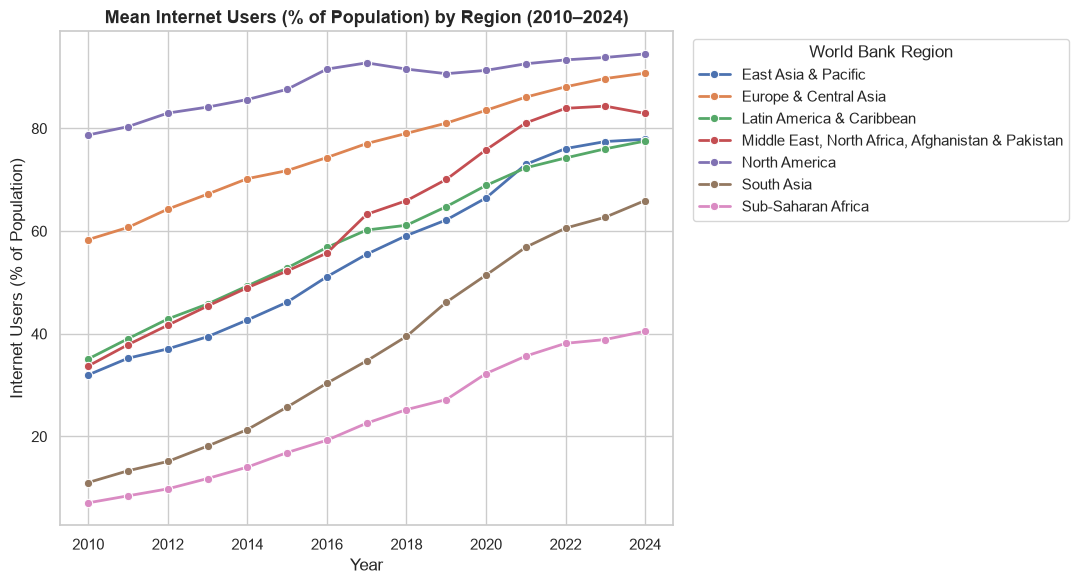

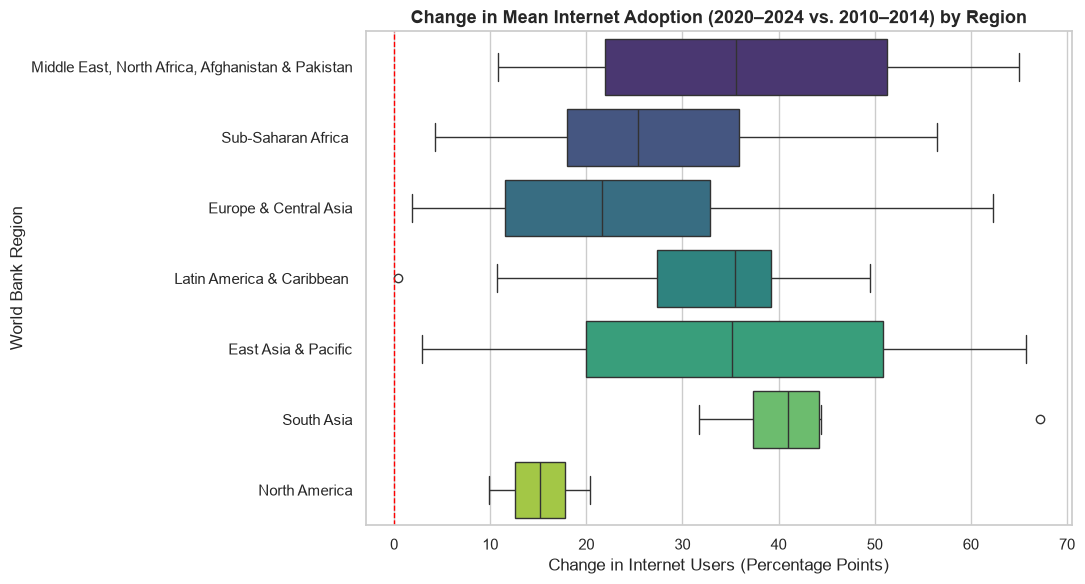

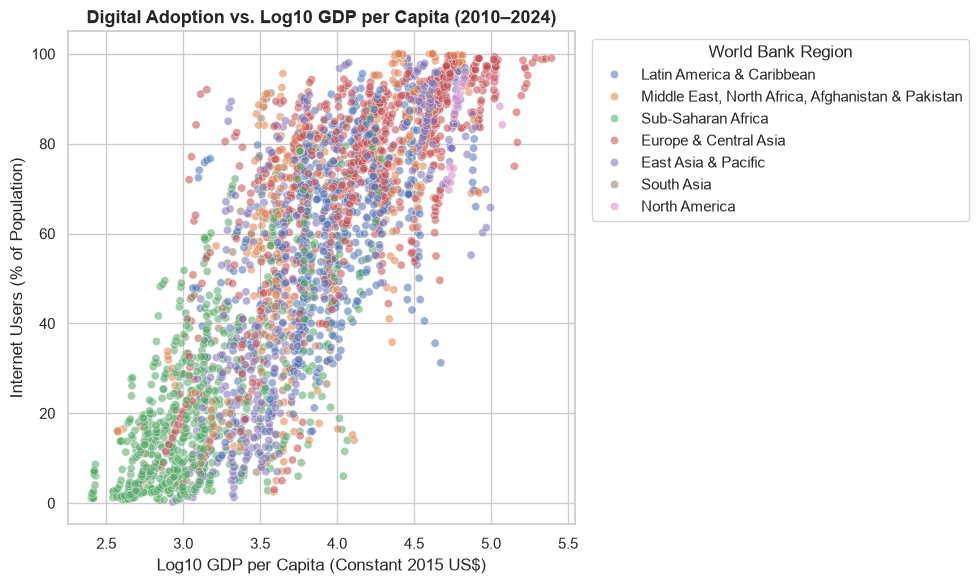

In [6]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Set clean visual styling for portfolio-grade charts
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

PROCESSED_DIR = "../data/processed"
panel = pd.read_csv(f"{PROCESSED_DIR}/digital_transformation_panel.csv")
period_df = pd.read_csv(f"{PROCESSED_DIR}/period_comparison_2010_2024.csv")

indicator_cols = [
    "internet_users",
    "fixed_broadband",
    "secure_servers",
    "ict_exports",
    "rd_expenditure",
    "gdp_per_capita",
]

# 1. Descriptive statistics for core indicators across the longitudinal panel
desc_panel = (
    panel[indicator_cols]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .T.round(2)
)
print("=== Longitudinal Panel Descriptive Statistics (2010-2024) ===")
display(desc_panel)

# 2. Descriptive statistics for period-over-period changes (2020-24 minus 2010-14)
delta_cols = [f"{col}_delta" for col in indicator_cols]
desc_delta = (
    period_df[delta_cols]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .T.round(2)
)
print("\n=== Five-Year Period Change Summary (2020-2024 vs. 2010-2014) ===")
display(desc_delta)

# 3. Chart A: Regional trajectory of internet users (2010-2024)
regional_trend = (
    panel.dropna(subset=["region", "internet_users"])
    .groupby(["region", "year"], as_index=False)["internet_users"]
    .mean()
)

plt.figure(figsize=(11, 6))
sns.lineplot(
    data=regional_trend,
    x="year",
    y="internet_users",
    hue="region",
    marker="o",
    linewidth=2,
)
plt.title(
    "Mean Internet Users (% of Population) by Region (2010–2024)",
    fontsize=13,
    weight="bold",
)
plt.xlabel("Year")
plt.ylabel("Internet Users (% of Population)")
plt.legend(
    title="World Bank Region", bbox_to_anchor=(1.02, 1), loc="upper left"
)
plt.tight_layout()
plt.show()

# 4. Chart B: Distribution of internet adoption change by region (2020-24 vs. 2010-14)
plot_delta = period_df.dropna(subset=["region", "internet_users_delta"]).copy()

plt.figure(figsize=(11, 6))
sns.boxplot(
    data=plot_delta,
    x="internet_users_delta",
    y="region",
    palette="viridis",
    hue="region",
    legend=False,
)
plt.axvline(0, color="red", linestyle="--", linewidth=1, label="Zero Change")
plt.title(
    "Change in Mean Internet Adoption (2020–2024 vs. 2010–2014) by Region",
    fontsize=13,
    weight="bold",
)
plt.xlabel("Change in Internet Users (Percentage Points)")
plt.ylabel("World Bank Region")
plt.tight_layout()
plt.show()

# 5. Chart C: Economic context vs. digital adoption (log GDP per capita vs. internet users)
econ_plot = panel.dropna(subset=["gdp_per_capita", "internet_users"]).copy()
econ_plot = econ_plot[econ_plot["gdp_per_capita"] > 0].copy()
econ_plot["log_gdp_pc"] = np.log10(econ_plot["gdp_per_capita"])

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=econ_plot,
    x="log_gdp_pc",
    y="internet_users",
    hue="region",
    alpha=0.55,
    s=35,
)
plt.title(
    "Digital Adoption vs. Log10 GDP per Capita (2010–2024)",
    fontsize=13,
    weight="bold",
)
plt.xlabel("Log10 GDP per Capita (Constant 2015 US$)")
plt.ylabel("Internet Users (% of Population)")
plt.legend(
    title="World Bank Region", bbox_to_anchor=(1.02, 1), loc="upper left"
)
plt.tight_layout()
plt.show()

In [10]:
panel

,country_code,country_name,region,income_group,year,internet_users,fixed_broadband,secure_servers,ict_exports,rd_expenditure,gdp_per_capita
0,ABW,Aruba,Latin America & Caribbean,High income,2010,62.000000,19.195118,88.375655,1.425195,NaN,25429.218097
1,ABW,Aruba,Latin America & Caribbean,High income,2011,69.000000,NaN,126.716769,1.472299,NaN,26093.054208
2,ABW,Aruba,Latin America & Caribbean,High income,2012,74.000000,NaN,249.735856,1.261810,NaN,25444.733665
3,ABW,Aruba,Latin America & Caribbean,High income,2013,78.900000,18.721114,416.370949,1.487310,NaN,26680.141121
4,ABW,Aruba,Latin America & Caribbean,High income,2014,83.780000,18.573515,552.398251,1.225307,NaN,26773.822910
...,...,...,...,...,...,...,...,...,...,...,...
3250,ZWE,Zimbabwe,Sub-Saharan Africa,Lower middle income,2020,29.298565,1.310378,71.295678,13.794328,NaN,1230.819334
3251,ZWE,Zimbabwe,Sub-Saharan Africa,Lower middle income,2021,32.592400,1.299805,75.899478,1.421957,NaN,1312.200014
3252,ZWE,Zimbabwe,Sub-Saharan Africa,Lower middle income,2022,36.256500,1.621502,78.100419,2.230362,NaN,1369.197615
3253,ZWE,Zimbabwe,Sub-Saharan Africa,Lower middle income,2023,38.674801,1.574578,89.346791,3.870194,NaN,1418.471846


In [11]:
period_df

,country_code,country_name,region,income_group,internet_users_2010_14,internet_users_2020_24,internet_users_delta,fixed_broadband_2010_14,fixed_broadband_2020_24,fixed_broadband_delta,...,secure_servers_delta,ict_exports_2010_14,ict_exports_2020_24,ict_exports_delta,rd_expenditure_2010_14,rd_expenditure_2020_24,rd_expenditure_delta,gdp_per_capita_2010_14,gdp_per_capita_2020_24,gdp_per_capita_delta
0,ABW,Aruba,Latin America & Caribbean,High income,NaN,NaN,NaN,18.829916,17.613995,-1.215921,...,1271.802234,1.374384,0.550102,-0.824283,NaN,NaN,NaN,26084.194000,28824.458030,2740.264030
1,AFG,Afghanistan,"Middle East, North Africa, Afghanistan & Pakistan",Low income,5.470900,16.290500,10.819600,0.004882,0.073537,0.068655,...,38.013778,NaN,NaN,NaN,NaN,NaN,NaN,558.595423,413.313807,-145.281616
2,AGO,Angola,Sub-Saharan Africa,Lower middle income,9.912468,36.461220,26.548752,0.123881,0.375480,0.251599,...,30.883081,3.540383,29.457292,25.916908,NaN,NaN,NaN,3642.885104,2796.194571,-846.690532
3,ALB,Albania,Europe & Central Asia,Upper middle income,49.500000,80.634912,31.134912,5.389800,21.087336,15.697536,...,1227.305394,5.798622,3.056584,-2.742038,NaN,NaN,NaN,3794.117127,5822.738904,2028.621777
4,AND,Andorra,Europe & Central Asia,High income,83.039999,93.953499,10.913499,34.879714,50.846707,15.966993,...,12358.228067,NaN,NaN,NaN,NaN,NaN,NaN,36621.304713,38539.458342,1918.153628
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
212,XKX,Kosovo,Europe & Central Asia,Upper middle income,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,9.753963,8.141190,-1.612773,NaN,NaN,NaN,3056.424850,4764.326735,1707.901885
213,YEM,"Yemen, Rep.","Middle East, North Africa, Afghanistan & Pakistan",Low income,NaN,NaN,NaN,0.659688,1.148490,0.488802,...,8.327473,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
214,ZAF,South Africa,Sub-Saharan Africa,Upper middle income,38.894000,76.413779,37.519779,2.242556,3.356710,1.114154,...,15191.278367,3.190552,8.643537,5.452985,0.674576,0.61055,-0.064026,6093.702067,5715.877014,-377.825053
215,ZMB,Zambia,Sub-Saharan Africa,Lower middle income,4.380000,15.603880,11.223880,0.100842,0.548629,0.447787,...,51.736342,3.656922,3.877345,0.220422,NaN,NaN,NaN,1246.090659,1294.188183,48.097524


### 4.1 Data Quality, Duplicates, Missingness, and Multicollinearity Audit

Before running confidence intervals, hypothesis tests, or panel regression models, we explicitly audit data integrity on `digital_transformation_panel.csv` (`panel`) and `period_comparison_2010_2024.csv` (`period_df`):
* **Duplicates:** Check both exact duplicate rows and duplicate `(country_code, year)` keys.
* **Missing Values Strategy:** Quantify missingness per indicator and year. Rather than imputing macroeconomic series artificially—which could distort distributions or create spurious relationships—we preserve observed values and evaluate each test/model on valid non-missing observations for the relevant variables.
* **Multicollinearity Check:** Compute pairwise correlations and Variance Inflation Factors (VIF) among candidate predictor variables (`gdp_per_capita`, `rd_expenditure`, `ict_exports`) to identify potential redundancy before panel regression.

Exact duplicate rows in panel: 0
Duplicate (country_code, year) keys in panel: 0


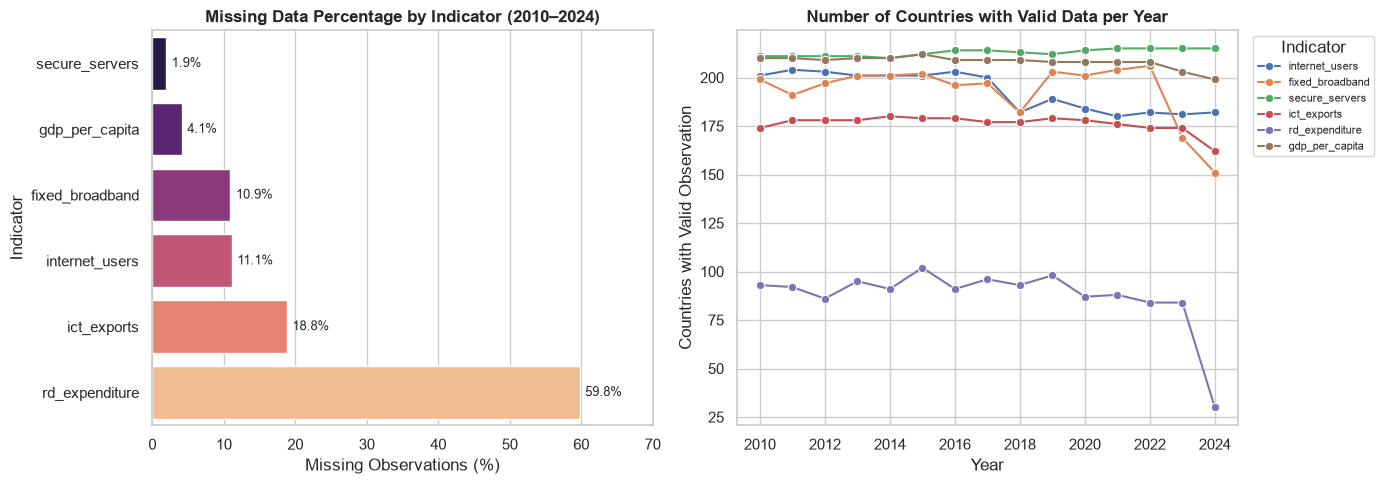

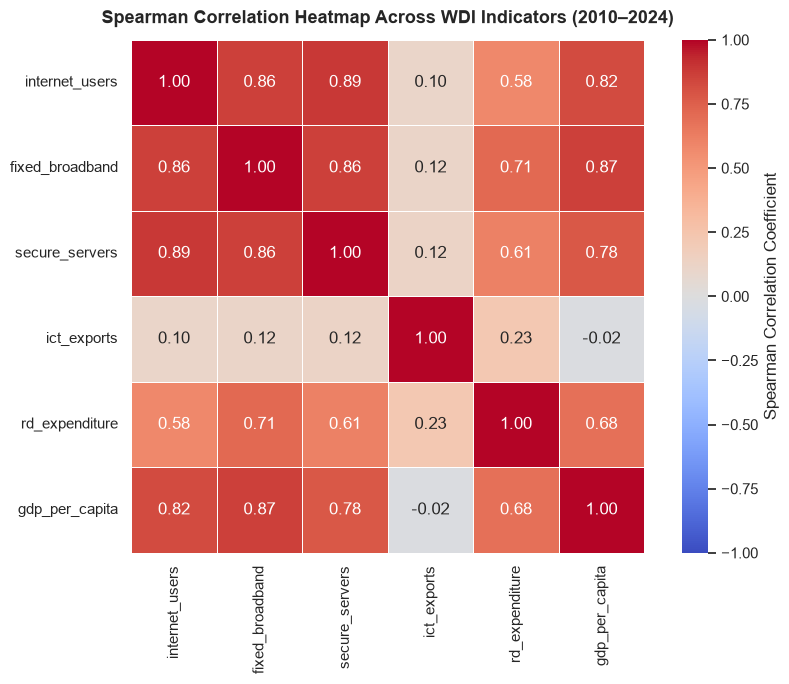


=== Variance Inflation Factor (VIF) on Complete Predictor Rows ===


,predictor,n_complete_rows,vif
0,gdp_per_capita,1235,1.71
1,rd_expenditure,1235,1.82
2,ict_exports,1235,1.10


In [13]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

PROCESSED_DIR = "../data/processed"
panel = pd.read_csv(f"{PROCESSED_DIR}/digital_transformation_panel.csv")
period_df = pd.read_csv(f"{PROCESSED_DIR}/period_comparison_2010_2024.csv")

indicator_cols = [
    "internet_users",
    "fixed_broadband",
    "secure_servers",
    "ict_exports",
    "rd_expenditure",
    "gdp_per_capita",
]

# 1. Check exact duplicates and duplicate (country_code, year) pairs
exact_dups = int(panel.duplicated().sum())
key_dups = int(panel.duplicated(subset=["country_code", "year"]).sum())
print(f"Exact duplicate rows in panel: {exact_dups}")
print(f"Duplicate (country_code, year) keys in panel: {key_dups}")

# 2. Missingness summary by indicator (count and percentage)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left plot: Overall missing percentage per indicator
missing_pct_sorted = (panel[indicator_cols].isna().mean() * 100).sort_values(
    ascending=True
)
sns.barplot(
    x=missing_pct_sorted.values,
    y=missing_pct_sorted.index,
    ax=axes[0],
    palette="magma",
    hue=missing_pct_sorted.index,
    legend=False,
)
axes[0].set_title(
    "Missing Data Percentage by Indicator (2010–2024)", fontsize=12, weight="bold"
)
axes[0].set_xlabel("Missing Observations (%)")
axes[0].set_ylabel("Indicator")
for i, v in enumerate(missing_pct_sorted.values):
  axes[0].text(v + 0.8, i, f"{v:.1f}%", va="center", fontsize=9)
axes[0].set_xlim(0, 70)

# Right plot: Annual data availability (non-null countries per year)
yearly_cov = (
    panel.groupby("year")[indicator_cols]
    .apply(lambda g: g.notna().sum())
    .reset_index()
)
yearly_melted = yearly_cov.melt(
    id_vars="year", var_name="indicator", value_name="valid_countries"
)
sns.lineplot(
    data=yearly_melted,
    x="year",
    y="valid_countries",
    hue="indicator",
    marker="o",
    ax=axes[1],
)
axes[1].set_title(
    "Number of Countries with Valid Data per Year", fontsize=12, weight="bold"
)
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Countries with Valid Observation")
axes[1].legend(
    title="Indicator", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8
)

plt.tight_layout()
plt.show()

# 3. Correlation matrix among numeric indicators + heatmap visualization
plt.figure(figsize=(9, 7))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={"label": "Spearman Correlation Coefficient"},
)
plt.title(
    "Spearman Correlation Heatmap Across WDI Indicators (2010–2024)",
    fontsize=13,
    weight="bold",
    pad=12,
)
plt.tight_layout()
plt.show()

# 4. Variance Inflation Factor (VIF) for candidate regression predictors
predictors = ["gdp_per_capita", "rd_expenditure", "ict_exports"]
vif_df = panel[predictors].dropna().copy()

if len(vif_df) > len(predictors) + 1:
  # Log-transform skewed positive variables for linear VIF diagnostic
  for col in predictors:
    if (vif_df[col] > 0).all():
      vif_df[col] = np.log(vif_df[col])

  X = vif_df.assign(const=1.0)
  vif_rows = []
  for i, col in enumerate(predictors):
    # Compute R^2 of regressing predictor i on all other columns in X
    other_cols = [c for c in X.columns if c != col]
    beta, *_ = np.linalg.lstsq(X[other_cols].values, X[col].values, rcond=None)
    pred = X[other_cols].values @ beta
    ss_res = np.sum((X[col].values - pred) ** 2)
    ss_tot = np.sum((X[col].values - X[col].values.mean()) ** 2)
    r2 = 1 - (ss_res / ss_tot) if ss_tot > 0 else 0.0
    vif = 1 / (1 - r2) if r2 < 0.9999 else np.inf
    vif_rows.append({
        "predictor": col,
        "n_complete_rows": len(vif_df),
        "vif": round(float(vif), 2),
    })
  print("\n=== Variance Inflation Factor (VIF) on Complete Predictor Rows ===")
  display(pd.DataFrame(vif_rows))
else:
  print("\nNot enough complete rows across all predictors to compute VIF.")

### 4.2 Interpretation of Data Integrity, Missingness, Correlation Heatmap, and VIF Diagnostics

#### 1. Data Integrity and Missing Values Strategy (Available-Case Analysis)
* **Zero Structural Duplication:** Integrity diagnostics confirm `0` exact duplicate rows and `0` duplicate `(country_code, year)` composite keys across the panel, verifying that the World Bank WDI API extraction produced a clean longitudinal structure.
* **Nature of Missing Values (`NaN`):** Missing entries reflect official reporting gaps by national statistical offices rather than parsing errors or corrupted characters. Core infrastructure and economic indicators exhibit high completeness (`secure_servers`: 1.90% missing; `gdp_per_capita`: 4.09% missing; `fixed_broadband`: 10.91% missing; `internet_users`: 11.09% missing), whereas `ict_exports` shows moderate missingness (18.80%) and `rd_expenditure` has substantial missingness (59.75%, with 1,310 valid country-year observations), as many developing economies report R&D surveys intermittently rather than annually.
* **Methodological Justification (No Artificial Imputation, No Global Row Deletion):**
  * We **do not impute** missing macroeconomic values using global means or interpolation, because artificial imputation on macro-level indicators distorts true variance, underestimates standard errors, and can introduce spurious statistical significance in hypothesis testing (Little and Rubin, 2019).
  * We **do not apply global listwise deletion** (`dropna()` across the entire dataset), because dropping every row missing `rd_expenditure` would discard nearly 60% of valid global observations for `internet_users`, `fixed_broadband`, and `secure_servers`, introducing severe selection bias toward high-income reporting economies.
  * Instead, we adopt **available-case (pairwise) analysis**: each inferential test and regression model uses all countries with complete, verified observations for the specific variables involved in that test (reporting exact sample sizes $n$ at every step). Consequently, analyses involving `rd_expenditure` explicitly evaluate the subset of countries with reliable multi-variable coverage, and this reporting asymmetry is documented as a formal study limitation.

#### 2. Spearman Correlation Heatmap Interpretation
* **Strong Positive Co-Movement Among Infrastructure & Economic Indicators:** The Spearman correlation heatmap reveals strong monotonic associations between `gdp_per_capita` and digital readiness metrics—specifically `fixed_broadband` ($\rho = 0.87$), `internet_users` ($\rho = 0.82$), and `secure_servers` ($\rho = 0.78$). Similarly, `internet_users`, `fixed_broadband`, and `secure_servers` correlate strongly with one another ($\rho = 0.86$ to $0.89$), reflecting that digital adoption, fixed connectivity, and secure hosting infrastructure tend to co-evolve within national ecosystems.
* **Moderate vs. Weak Associations:** `rd_expenditure` displays a moderate-to-strong positive correlation with `fixed_broadband` ($\rho = 0.71$), `gdp_per_capita` ($\rho = 0.68$), and `secure_servers` ($\rho = 0.61$), whereas `ict_exports` exhibits weak bivariate correlations with general infrastructure ($\rho = 0.10$ to $0.12$), indicating that export-oriented ICT service hubs do not always mirror domestic broadband penetration.
* **Why High Outcome Correlations Do Not Harm Regression:** Because `internet_users`, `fixed_broadband`, and `secure_servers` serve as separate outcome indicators rather than simultaneous predictors in the same regression equation, their high inter-correlation does not create collinearity issues.

#### 3. Variance Inflation Factor (VIF) Assessment
* **Low Multicollinearity Confirmed:** Evaluating the three candidate regression predictors (`gdp_per_capita`, `rd_expenditure`, and `ict_exports`) across $n = 1,235$ complete rows yields Variance Inflation Factors of **1.71**, **1.82**, and **1.10**, respectively.
* **Statistical Decision:** All VIF values fall well below the conservative threshold of `5.0` (Hair et al., 2019), confirming that economic output, R&D investment, and ICT service exports capture distinct structural dimensions without harmful multicollinearity. All three predictors are therefore retained for subsequent panel modeling.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")

cols_num = [
    "internet_users",
    "fixed_broadband",
    "secure_servers",
    "ict_exports",
    "rd_expenditure",
    "gdp_per_capita",
]

# 1A. Boxplots en escala original (útil para ver asimetría y outliers extremos)
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for ax, col in zip(axes, cols_num):
  s = period[col].dropna()
  sns.boxplot(x=s, ax=ax, color="#4C72B0", fliersize=3)
  ax.set_title(f"Boxplot: {col}", fontsize=11, fontweight="bold")
  ax.set_xlabel("")

plt.suptitle(
    "Distribución y valores atípicos (escala original, 2010–2024)",
    fontsize=13,
    fontweight="bold",
)
plt.tight_layout()
plt.show()

# 1B. Boxplots en escala logarítmica para variables con fuerte asimetría a la derecha
skewed_cols = ["secure_servers", "gdp_per_capita", "rd_expenditure"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for ax, col in zip(axes, skewed_cols):
  # np.log1p evita problemas si hay ceros
  s_log = np.log1p(df[col].clip(lower=0).dropna())
  sns.boxplot(x=s_log, ax=ax, color="#55A868", fliersize=3)
  ax.set_title(f"log1p({col})", fontsize=11, fontweight="bold")
  ax.set_xlabel("Valor transformado (log1p)")

plt.suptitle(
    "Variables asimétricas en escala logarítmica", fontsize=13, fontweight="bold"
)
plt.tight_layout()
plt.show()

## Exploratory Data Analysis: Outliers and Skewness
##### Boxplots in the original scale highlight right skewness and extreme values across WDI indicators, 
##### while `log1p`-transformed boxplots clarify distributions for heavily skewed variables.


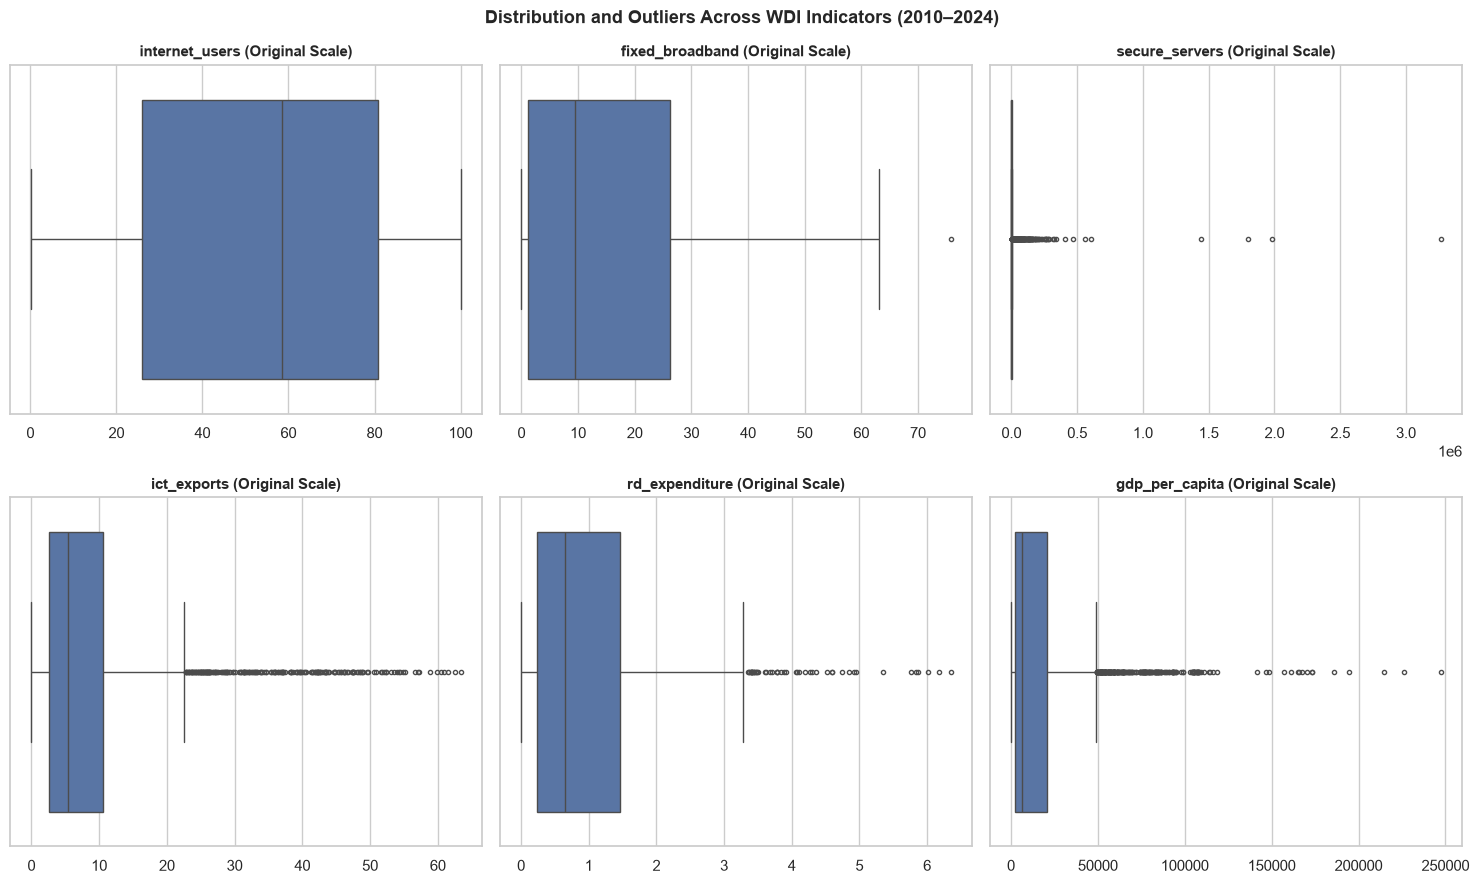

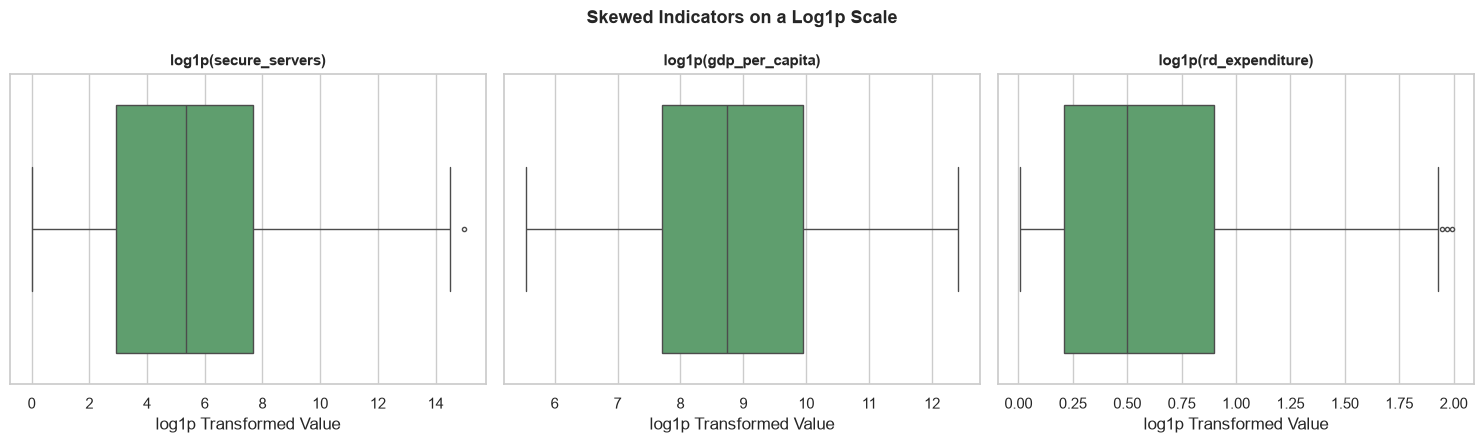

In [14]:


import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

sns.set_theme(style="whitegrid")

indicator_cols = [
    "internet_users",
    "fixed_broadband",
    "secure_servers",
    "ict_exports",
    "rd_expenditure",
    "gdp_per_capita",
]

# Boxplots on the original scale
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for ax, col in zip(axes, indicator_cols):
  series = panel[col].dropna()
  sns.boxplot(x=series, ax=ax, color="#4C72B0", fliersize=3)
  ax.set_title(f"{col} (Original Scale)", fontsize=11, fontweight="bold")
  ax.set_xlabel("")

fig.suptitle(
    "Distribution and Outliers Across WDI Indicators (2010–2024)",
    fontsize=13,
    fontweight="bold",
)
plt.tight_layout()
plt.show()

# Boxplots on a log1p scale for right-skewed indicators
skewed_cols = ["secure_servers", "gdp_per_capita", "rd_expenditure"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for ax, col in zip(axes, skewed_cols):
  log_series = np.log1p(panel[col].clip(lower=0).dropna())
  sns.boxplot(x=log_series, ax=ax, color="#55A868", fliersize=3)
  ax.set_title(f"log1p({col})", fontsize=11, fontweight="bold")
  ax.set_xlabel("log1p Transformed Value")

fig.suptitle(
    "Skewed Indicators on a Log1p Scale", fontsize=13, fontweight="bold"
)
plt.tight_layout()
plt.show()

Reference: Little, R. J., & Rubin, D. B. (2019). Statistical Analysis with Missing Data (3rd ed.). John Wiley & Sons. (This third edition accurately covers the pitfalls of single imputation and deterministic interpolation on variance and standard errors).